In [ ]:
!rm -f /content/*.csv

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")
print("Libraries loaded.")

Libraries loaded.


In [ ]:
try:
    from google.colab import files
    uploaded = files.upload()          # choose vehicle.csv
    csv_name = list(uploaded.keys())[0]   # use the exact name Colab saved it under
except ImportError:
    csv_name = "vehicle.csv"           # running outside Colab

df = pd.read_csv(csv_name)
print("Loaded file:", csv_name)
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
df.head()

Saving vehicle[1].csv to vehicle[1].csv
Loaded file: vehicle[1].csv
Shape: (846, 19)
Missing values: 0


,COMPACTNESS,CIRCULARITY,DISTANCE CIRCULARITY,RADIUS RATIO,PR AXIS ASPECT RATIO,MAX LENGTH ASPECT RATIO,SCATTER RATIO,ELONGATEDNESS,PR AXISRECTANGULAR,LENGTHRECTANGULAR,MAJORVARIANCE,MINORVARIANCE,GYRATIONRADIUS,MAJORSKEWNESS,MINORSKEWNESS,MINORKURTOSIS,MAJORKURTOSIS,HOLLOWS RATIO,target
0,95.0,43.0,96.0,202.0,65.0,10.0,189.0,35.0,22.0,143.0,217.0,534.0,166.0,71.0,6.0,27.0,190.0,197.0,1
1,96.0,52.0,104.0,222.0,67.0,9.0,198.0,33.0,23.0,163.0,217.0,589.0,226.0,67.0,12.0,20.0,192.0,201.0,1
2,107.0,52.0,101.0,218.0,64.0,11.0,202.0,33.0,23.0,164.0,219.0,610.0,192.0,65.0,17.0,2.0,197.0,206.0,1
3,97.0,37.0,78.0,181.0,62.0,8.0,161.0,41.0,20.0,131.0,182.0,389.0,117.0,62.0,2.0,28.0,203.0,211.0,1
4,96.0,54.0,104.0,175.0,58.0,10.0,215.0,31.0,24.0,175.0,221.0,682.0,222.0,75.0,13.0,23.0,186.0,194.0,1


                           min     max        mean         std
COMPACTNESS               73.0   119.0   93.678487    8.234474
CIRCULARITY               33.0    59.0   44.861702    6.169866
DISTANCE CIRCULARITY      40.0   112.0   82.088652   15.771533
RADIUS RATIO             104.0   333.0  168.940898   33.472183
PR AXIS ASPECT RATIO      47.0   138.0   61.693853    7.888251
MAX LENGTH ASPECT RATIO    2.0    55.0    8.567376    4.601217
SCATTER RATIO            112.0   265.0  168.839243   33.244978
ELONGATEDNESS             26.0    61.0   40.933806    7.811560
PR AXISRECTANGULAR        17.0    29.0   20.582742    2.592138
LENGTHRECTANGULAR        118.0   188.0  147.998818   14.515652
MAJORVARIANCE            130.0   320.0  188.625296   31.394837
MINORVARIANCE            184.0  1018.0  439.911348  176.692614
GYRATIONRADIUS           109.0   268.0  174.703310   32.546490
MAJORSKEWNESS             59.0   135.0   72.462175    7.486974
MINORSKEWNESS              0.0    22.0    6.377069    4

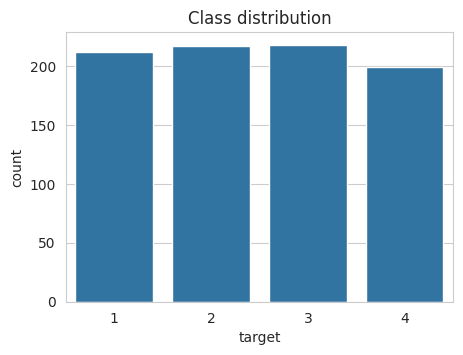

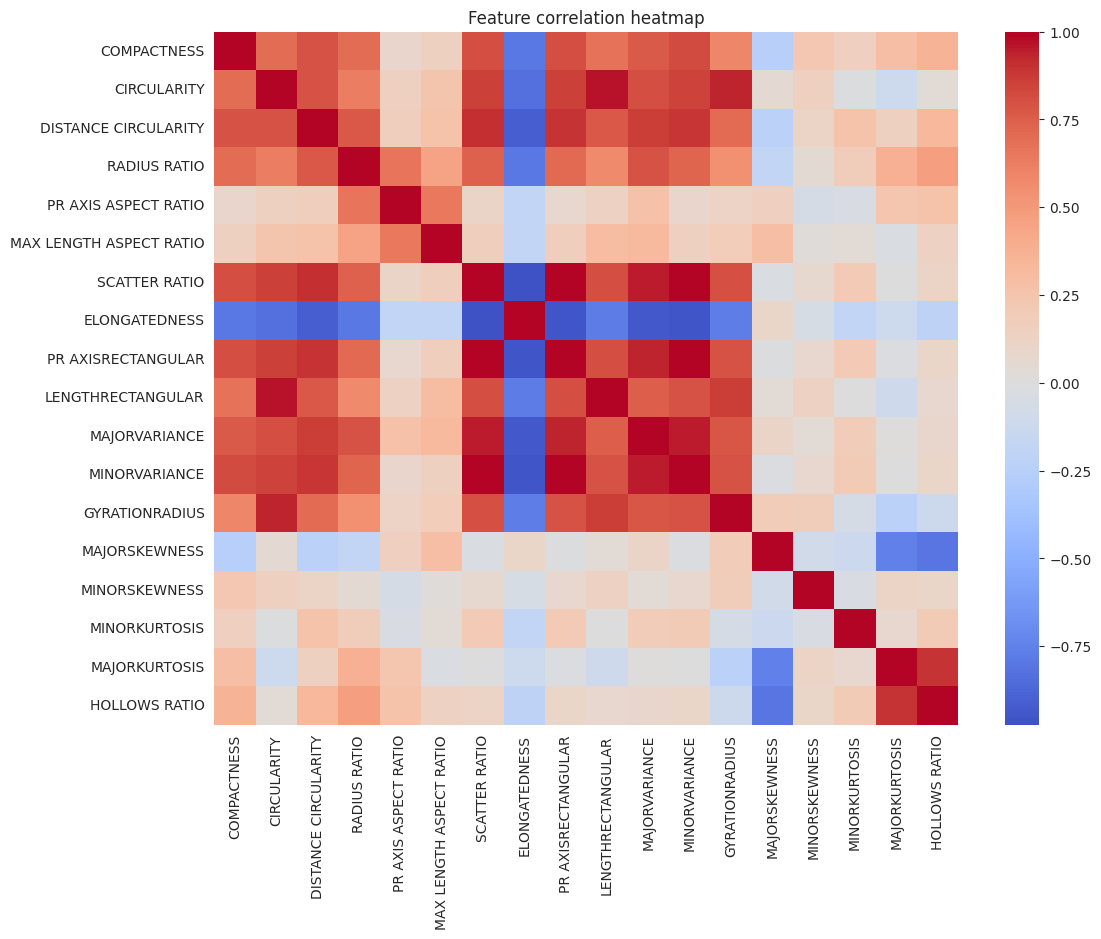

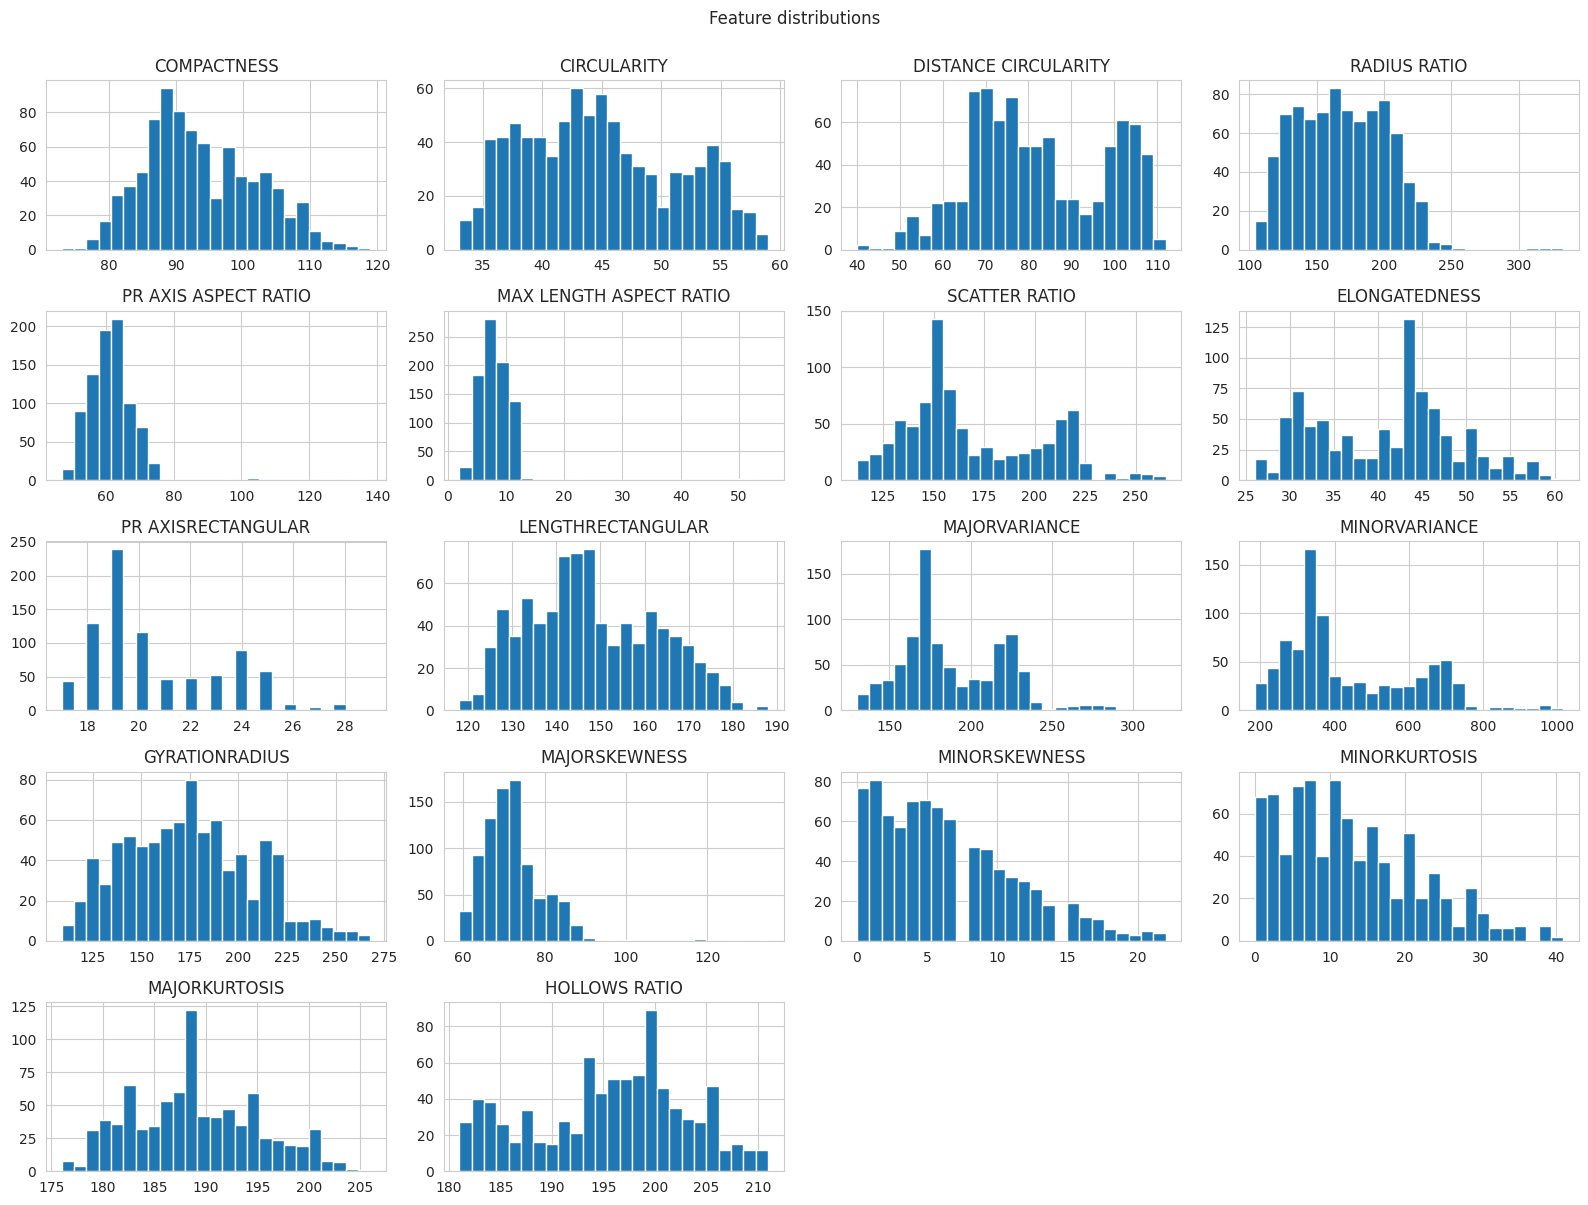

In [ ]:
print(df.describe().T[["min", "max", "mean", "std"]])

plt.figure(figsize=(5, 3.5))
sns.countplot(x="target", data=df)
plt.title("Class distribution")
plt.show()

plt.figure(figsize=(12, 9))
sns.heatmap(df.drop(columns="target").corr(), cmap="coolwarm", center=0)
plt.title("Feature correlation heatmap")
plt.show()

df.drop(columns="target").hist(figsize=(16, 12), bins=25)
plt.suptitle("Feature distributions", y=1.0)
plt.tight_layout()
plt.show()

In [ ]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train size:", X_train.shape[0], "| Test size:", X_test.shape[0])
print("Train class share:\n", y_train.value_counts(normalize=True).round(3))

Train size: 676 | Test size: 170
Train class share:
 target
3    0.257
2    0.256
1    0.251
4    0.235
Name: proportion, dtype: float64


In [ ]:
baseline = KNeighborsClassifier(n_neighbors=5)
baseline.fit(X_train, y_train)
baseline_acc = accuracy_score(y_test, baseline.predict(X_test))
print(f"Baseline accuracy (K=5, no scaling): {baseline_acc:.4f}")

Baseline accuracy (K=5, no scaling): 0.6529


In [ ]:
scaled_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])
scaled_pipe.fit(X_train, y_train)
scaled_acc = accuracy_score(y_test, scaled_pipe.predict(X_test))
print(f"Scaled accuracy (K=5, StandardScaler): {scaled_acc:.4f}")
print(f"Improvement over baseline: {scaled_acc - baseline_acc:+.4f}")

Scaled accuracy (K=5, StandardScaler): 0.7059
Improvement over baseline: +0.0529


Best K by 5-fold cross-validation: 3 (CV accuracy = 0.6908)


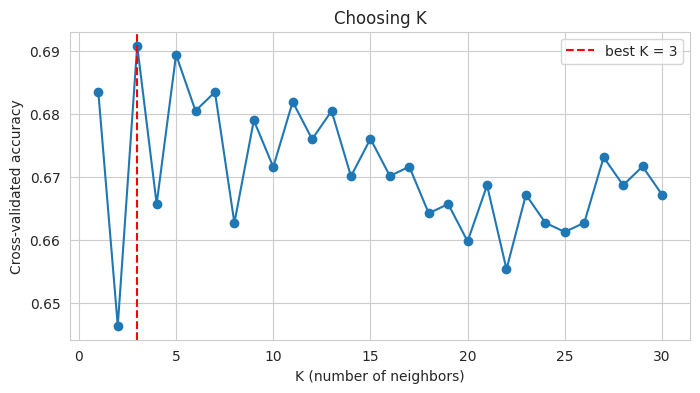

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
k_values = range(1, 31)
cv_scores = []

for k in k_values:
    pipe = Pipeline([("scaler", StandardScaler()),
                     ("knn", KNeighborsClassifier(n_neighbors=k))])
    cv_scores.append(cross_val_score(pipe, X_train, y_train, cv=cv).mean())

best_k = list(k_values)[int(np.argmax(cv_scores))]
print(f"Best K by 5-fold cross-validation: {best_k} (CV accuracy = {max(cv_scores):.4f})")

plt.figure(figsize=(8, 4))
plt.plot(k_values, cv_scores, marker="o")
plt.axvline(best_k, color="red", linestyle="--", label=f"best K = {best_k}")
plt.xlabel("K (number of neighbors)")
plt.ylabel("Cross-validated accuracy")
plt.title("Choosing K")
plt.legend()
plt.show()

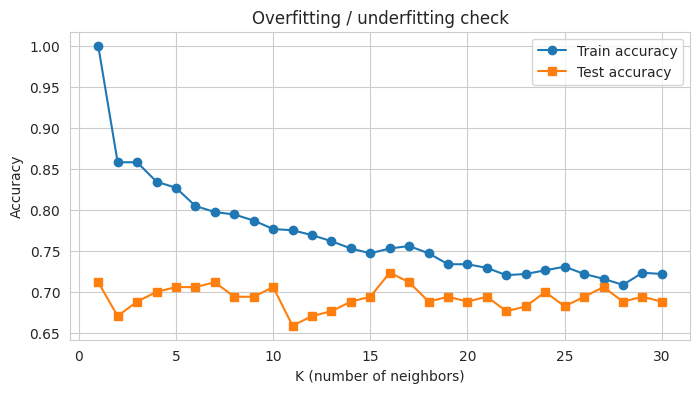

Gap (train - test) at K=1  : 0.2882
Gap (train - test) at K=3: 0.1698
Gap (train - test) at K=30 : 0.0337


In [ ]:
train_acc, test_acc = [], []

for k in k_values:
    pipe = Pipeline([("scaler", StandardScaler()),
                     ("knn", KNeighborsClassifier(n_neighbors=k))])
    pipe.fit(X_train, y_train)
    train_acc.append(pipe.score(X_train, y_train))
    test_acc.append(pipe.score(X_test, y_test))

plt.figure(figsize=(8, 4))
plt.plot(k_values, train_acc, marker="o", label="Train accuracy")
plt.plot(k_values, test_acc, marker="s", label="Test accuracy")
plt.xlabel("K (number of neighbors)")
plt.ylabel("Accuracy")
plt.title("Overfitting / underfitting check")
plt.legend()
plt.show()

gap = np.array(train_acc) - np.array(test_acc)
print(f"Gap (train - test) at K=1  : {gap[0]:.4f}")
print(f"Gap (train - test) at K={best_k}: {gap[best_k - 1]:.4f}")
print(f"Gap (train - test) at K=30 : {gap[-1]:.4f}")

In [ ]:
pipe = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier())])

param_grid = {
    "knn__n_neighbors": list(range(1, 31)),
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan", "minkowski"],
}

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print(f"Best CV accuracy: {grid.best_score_:.4f}")

results = pd.DataFrame(grid.cv_results_)
top5 = results.sort_values("rank_test_score").head(5)[
    ["param_knn__n_neighbors", "param_knn__weights", "param_knn__metric",
     "mean_test_score", "std_test_score"]]
print("\nTop 5 combinations:")
print(top5.to_string(index=False))

tuned_model = grid.best_estimator_
tuned_acc = accuracy_score(y_test, tuned_model.predict(X_test))
print(f"\nTuned test accuracy: {tuned_acc:.4f}")

Best parameters: {'knn__metric': 'manhattan', 'knn__n_neighbors': 9, 'knn__weights': 'distance'}
Best CV accuracy: 0.7101

Top 5 combinations:
 param_knn__n_neighbors param_knn__weights param_knn__metric  mean_test_score  std_test_score
                      9           distance         manhattan         0.710109        0.033090
                     21           distance         manhattan         0.708606        0.024269
                     25           distance         manhattan         0.707146        0.026176
                      7           distance         manhattan         0.707146        0.026592
                     19           distance         manhattan         0.707146        0.023526

Tuned test accuracy: 0.7176


Components needed to keep 95% of variance: 7 (out of 18)


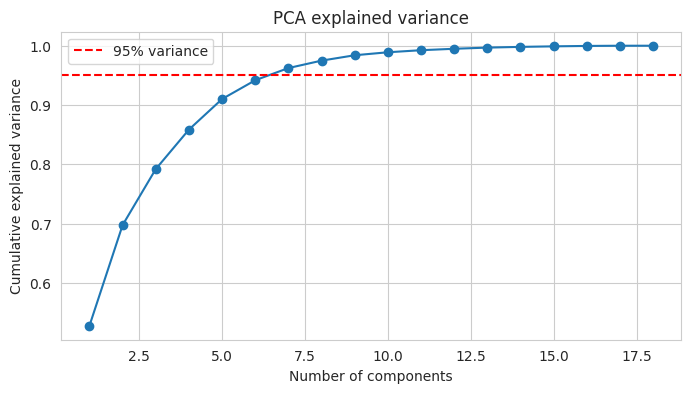

PCA + KNN  -> CV accuracy: 0.6657 | Test accuracy: 0.7118
Tuned KNN  -> CV accuracy: 0.7101 | Test accuracy: 0.7176


In [34]:
pca_full = Pipeline([("scaler", StandardScaler()), ("pca", PCA(random_state=RANDOM_STATE))])
pca_full.fit(X_train)
cum_var = np.cumsum(pca_full.named_steps["pca"].explained_variance_ratio_)
n_95 = int(np.argmax(cum_var >= 0.95) + 1)
print(f"Components needed to keep 95% of variance: {n_95} (out of {X.shape[1]})")

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker="o")
plt.axhline(0.95, color="red", linestyle="--", label="95% variance")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA explained variance")
plt.legend()
plt.show()

best = grid.best_params_
pca_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=n_95, random_state=RANDOM_STATE)),
    ("knn", KNeighborsClassifier(n_neighbors=best["knn__n_neighbors"],
                                 weights=best["knn__weights"],
                                 metric=best["knn__metric"]))
])
pca_cv = cross_val_score(pca_pipe, X_train, y_train, cv=cv).mean()
pca_pipe.fit(X_train, y_train)
pca_acc = accuracy_score(y_test, pca_pipe.predict(X_test))
print(f"PCA + KNN  -> CV accuracy: {pca_cv:.4f} | Test accuracy: {pca_acc:.4f}")
print(f"Tuned KNN  -> CV accuracy: {grid.best_score_:.4f} | Test accuracy: {tuned_acc:.4f}")

In [35]:
def add_noise(X_df, y_series, copies=1, noise_level=0.05, seed=RANDOM_STATE):
    """Create noisy copies of TRAINING rows only (noise = fraction of each feature's std)."""
    rng = np.random.default_rng(seed)
    stds = X_df.std().values
    X_parts, y_parts = [X_df.values], [y_series.values]
    for _ in range(copies):
        X_parts.append(X_df.values + rng.normal(0, noise_level * stds, X_df.shape))
        y_parts.append(y_series.values)
    return pd.DataFrame(np.vstack(X_parts), columns=X_df.columns), pd.Series(np.concatenate(y_parts))

aug_results = []
for level in [0.02, 0.05, 0.10]:
    X_aug, y_aug = add_noise(X_train, y_train, copies=1, noise_level=level)
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=best["knn__n_neighbors"],
                                     weights=best["knn__weights"],
                                     metric=best["knn__metric"]))
    ])
    model.fit(X_aug, y_aug)
    aug_results.append((level, len(X_aug), accuracy_score(y_test, model.predict(X_test))))

print(f"Reference (no augmentation): {tuned_acc:.4f}\n")
for level, n, acc in aug_results:
    print(f"noise={level:.2f} | training rows={n} | test accuracy={acc:.4f} | change={acc - tuned_acc:+.4f}")

Reference (no augmentation): 0.7176

noise=0.02 | training rows=1352 | test accuracy=0.6824 | change=-0.0353
noise=0.05 | training rows=1352 | test accuracy=0.6706 | change=-0.0471
noise=0.10 | training rows=1352 | test accuracy=0.6824 | change=-0.0353


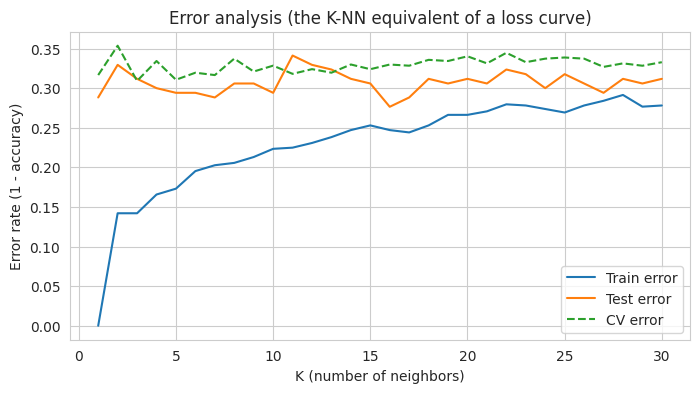

In [36]:
error_cv = [1 - s for s in cv_scores]
error_train = [1 - a for a in train_acc]
error_test = [1 - a for a in test_acc]

plt.figure(figsize=(8, 4))
plt.plot(k_values, error_train, label="Train error")
plt.plot(k_values, error_test, label="Test error")
plt.plot(k_values, error_cv, label="CV error", linestyle="--")
plt.xlabel("K (number of neighbors)")
plt.ylabel("Error rate (1 - accuracy)")
plt.title("Error analysis (the K-NN equivalent of a loss curve)")
plt.legend()
plt.show()

Final test accuracy: 0.7176

              precision    recall  f1-score   support

           1       0.50      0.43      0.46        42
           2       0.55      0.50      0.52        44
           3       0.95      0.95      0.95        44
           4       0.80      1.00      0.89        40

    accuracy                           0.72       170
   macro avg       0.70      0.72      0.71       170
weighted avg       0.70      0.72      0.71       170



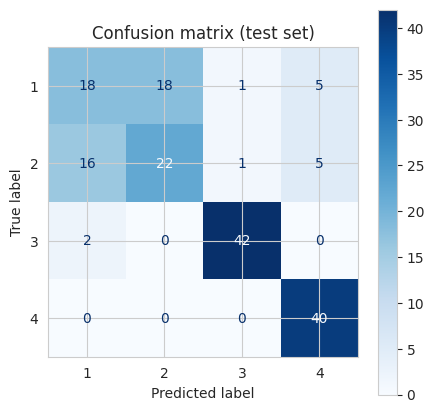

In [37]:
final_model = tuned_model
final_pred = final_model.predict(X_test)
final_acc = accuracy_score(y_test, final_pred)

print(f"Final test accuracy: {final_acc:.4f}\n")
print(classification_report(y_test, final_pred))

fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(y_test, final_pred, cmap="Blues", ax=ax)
ax.set_title("Confusion matrix (test set)")
plt.show()

                          Model  Test accuracy
     Baseline (K=5, no scaling)         0.6529
                   Scaled (K=5)         0.7059
           Tuned (GridSearchCV)         0.7176
      PCA (7 comps) + tuned KNN         0.7118
Tuned + best noise augmentation         0.6824


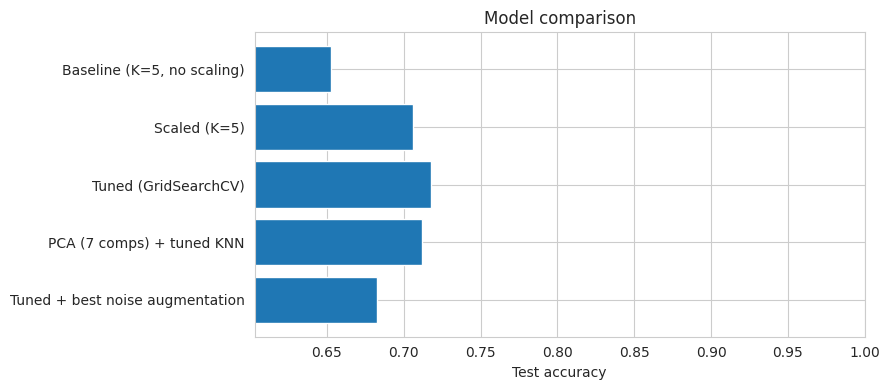

In [38]:
best_aug_acc = max(a for _, _, a in aug_results)

summary = pd.DataFrame({
    "Model": ["Baseline (K=5, no scaling)", "Scaled (K=5)", "Tuned (GridSearchCV)",
              f"PCA ({n_95} comps) + tuned KNN", "Tuned + best noise augmentation"],
    "Test accuracy": [baseline_acc, scaled_acc, tuned_acc, pca_acc, best_aug_acc],
}).round(4)

print(summary.to_string(index=False))

plt.figure(figsize=(9, 4))
plt.barh(summary["Model"], summary["Test accuracy"])
plt.xlim(summary["Test accuracy"].min() - 0.05, 1.0)
plt.xlabel("Test accuracy")
plt.title("Model comparison")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()